# SolarSentinel – the project explained

### How to use this notebook

Read it top to bottom: from the Sun, to the satellite at L1, to Earth, to our model.
Section 4 loads **live data** (internet needed), section 5 loads **our own data** from `_data/`.

- Kernel: `.venv` (after `uv sync` in the repo root)
- Terms you don't know: [glossary.md](glossary.md)

## 1. What is this about?

### Problem, goal, data

| | |
|---|---|
| **Problem** | The official Kp index (how disturbed Earth's magnetic field is, 0–9) is only published every **3 hours**. |
| **Goal** | Predict Kp every **few minutes** from real-time solar wind data. |
| **Why it matters** | Strong storms (Kp 8–9) disturb power grids, satellites, GPS and radio. Operators need a warning. |
| **Data** | NASA OMNI: solar wind every minute since 1981, Kp/Dst every hour since 1963 + NOAA live data. |

### Team

| Name | Role |
|---|---|
| Alex | GitHub, code, models |
| Karl | Project documentation |
| Nooshin | Science behind it |

## 2. The big picture

### From the Sun to a storm warning

![project sketch](project_sketch.png)

1. **Sun:** an eruption (CME) or a coronal hole sends out charged particles with a magnetic field.
2. **Space:** they travel ~150 million km, usually 1–3 days. (Not light years: one light year is ~9.5 trillion km.)
3. **L1:** satellites ~1.5 million km in front of Earth measure the solar wind **before** it arrives.
4. **Earth:** if the field of the solar wind points south (**Bz < 0**), it connects to Earth's field and energy flows in.
5. **Ground:** magnetometers measure the disturbance → K → Kp → NOAA G-scale.

**SolarSentinel works between step 3 and 4:** the 30–90 minutes the solar wind needs from L1 to Earth.

### Why Bz < 0 is the key

Earth's magnetic field points north on the day side.
If the solar wind field points **south**, the two fields connect like two magnets and energy flows into the magnetosphere.
A fast solar wind with Bz > 0 often stays harmless. A medium one with strongly negative Bz for hours can become a big storm.

## 3. How storms are measured

### How Kp is made

1. ~13 magnetometer stations worldwide (mid latitudes) look at a **3-hour window**.
2. Each station takes the largest swing of the horizontal magnetic field, minus the normal daily variation → **K** (0–9).
3. All stations are normalised and averaged → **Kp** ("p" = planetary).

- The scale is roughly **logarithmic**: Kp 8 is many times stronger than Kp 4, not twice.
- Kp comes in **thirds**: `5-` = 4.67 · `5o` = 5.00 · `5+` = 5.33.
- Official publisher: **GFZ Potsdam**. NOAA publishes its own fast version.
- Finer versions exist: estimated Kp every minute (NOAA), **Hp30** every 30 min and open above 9 (GFZ).

### Kp → storm class (NOAA G-scale)

| Kp | Class | Per 11-year cycle | What happens | Aurora down to |
|---|---|---|---|---|
| 0–4 | G0 | – | no storm | far north only |
| 5 | G1 minor | ~900 days | small grid fluctuations | Scandinavia |
| 6 | G2 moderate | ~360 days | voltage alarms in the north | ~55° geomagn. |
| 7 | G3 strong | ~130 days | satellites charge up, GPS errors | ~50° |
| 8 | **G4 severe** | ~60 days | voltage problems in the grid, GPS off for hours, HF radio disturbed | ~45° |
| 9 | **G5 extreme** | ~4 days | grid collapse possible, transformer damage, GPS off for days, satellites sink | ~40° (all of Germany) |

Source: NOAA SWPC Space Weather Scales. Open question: `5-` (4.67) counts as G0 in our code – check NOAA's rule before the model uses it.

### Three different "solar storms"

| Scale | What | Arrives after | Main effect | Our project? |
|---|---|---|---|---|
| **R** radio blackout | flare (X-rays, UV) | ~8 min | HF radio out on the day side | no |
| **S** radiation storm | very fast protons | ~10 min to hours | radiation for astronauts, polar flights | no |
| **G** geomagnetic storm | CME / fast solar wind | 1–3 days | grid, GPS, satellites, aurora | **yes – this is Kp** |

A strong flare does not automatically mean a strong G-storm. What counts is whether a CME hits Earth and how Bz points.

## 4. Live data: what is happening right now

In [1]:
# imports and helper for the free NOAA / GFZ live APIs (no key needed)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

NOAA = "https://services.swpc.noaa.gov"

def get_json(url, **params):
    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()
    return r.json()

In [2]:
# NOAA storm classes (G-scale) by Kp
G_SCALE = {"G0 no storm": (0, 5), "G1 minor": (5, 6), "G2 moderate": (6, 7),
           "G3 strong": (7, 8), "G4 severe": (8, 9), "G5 extreme": (9, 10)}

def g_class(kp):
    # shortcut: Kp 5- (4.67) counts as G0 here, check NOAA's rule before using it in the model
    for name, (lo, hi) in G_SCALE.items():
        if lo <= kp < hi:
            return name

assert g_class(4.67) == "G0 no storm" and g_class(5.0) == "G1 minor" and g_class(9.0) == "G5 extreme"

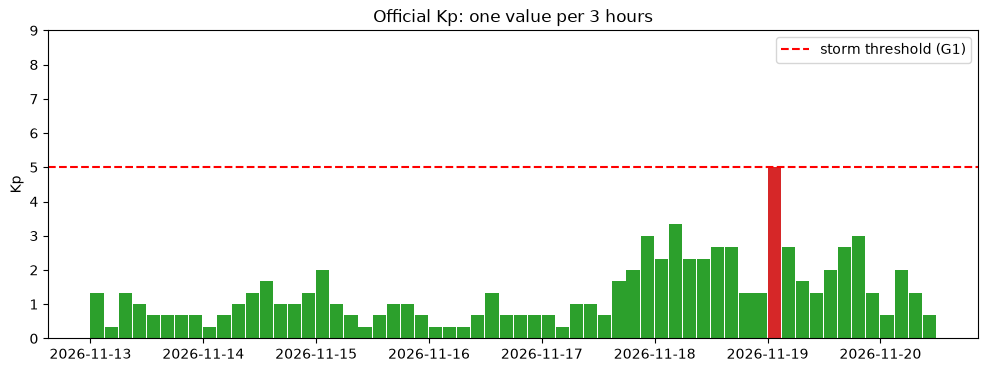

In [3]:
# official Kp from NOAA, last 7 days (time = start of each 3-hour window)
kp3 = pd.DataFrame(get_json(f"{NOAA}/products/noaa-planetary-k-index.json"))
kp3["time"] = pd.to_datetime(kp3["time_tag"], utc=True)
kp3["class"] = kp3["Kp"].apply(g_class)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(kp3["time"], kp3["Kp"], width=pd.Timedelta(hours=2.8), align="edge",
       color=["tab:red" if kp >= 5 else "tab:green" for kp in kp3["Kp"]])
ax.axhline(5, color="red", ls="--", label="storm threshold (G1)")
ax.set(ylim=(0, 9), ylabel="Kp", title="Official Kp: one value per 3 hours")
ax.legend()
plt.show()

In [4]:
# today (UTC): how often was Kp in each storm class
today = pd.Timestamp.now(tz="UTC").normalize()
kp_today = kp3[kp3["time"] >= today]
print(f"{len(kp_today)} of 8 three-hour windows of today are published")
kp_today["class"].value_counts().reindex(list(G_SCALE), fill_value=0)

4 of 8 three-hour windows of today are published


class
G0 no storm    4
G1 minor       0
G2 moderate    0
G3 strong      0
G4 severe      0
G5 extreme     0
Name: count, dtype: int64

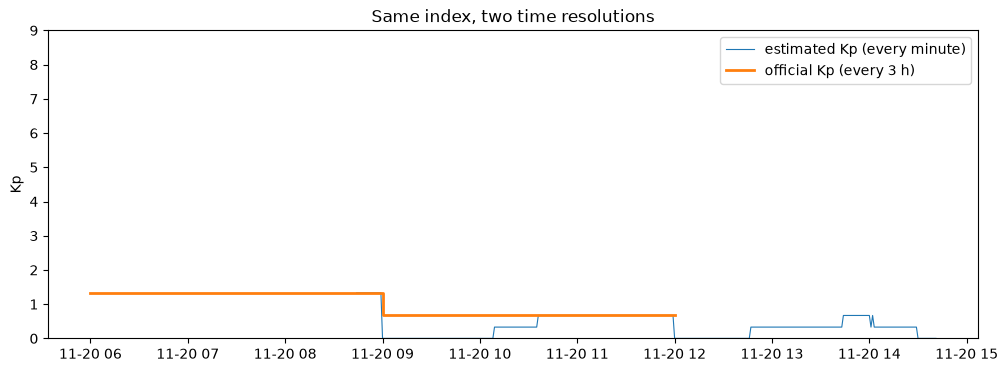

In [5]:
# NOAA estimated Kp every minute vs the official 3-hour steps
kp1 = pd.DataFrame(get_json(f"{NOAA}/json/planetary_k_index_1m.json"))
kp1["time"] = pd.to_datetime(kp1["time_tag"], utc=True)
kp_recent = kp3[kp3["time"] >= kp1["time"].min() - pd.Timedelta(hours=3)]
# repeat the last value 3 h later so the last window is drawn as a full step
kp_recent = pd.concat([kp_recent, kp_recent.tail(1).assign(time=lambda d: d["time"] + pd.Timedelta(hours=3))])

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(kp1["time"], kp1["estimated_kp"], lw=0.8, label="estimated Kp (every minute)")
ax.step(kp_recent["time"], kp_recent["Kp"], where="post", lw=2, label="official Kp (every 3 h)")
ax.set(ylim=(0, 9), ylabel="Kp", title="Same index, two time resolutions")
ax.legend()
plt.show()

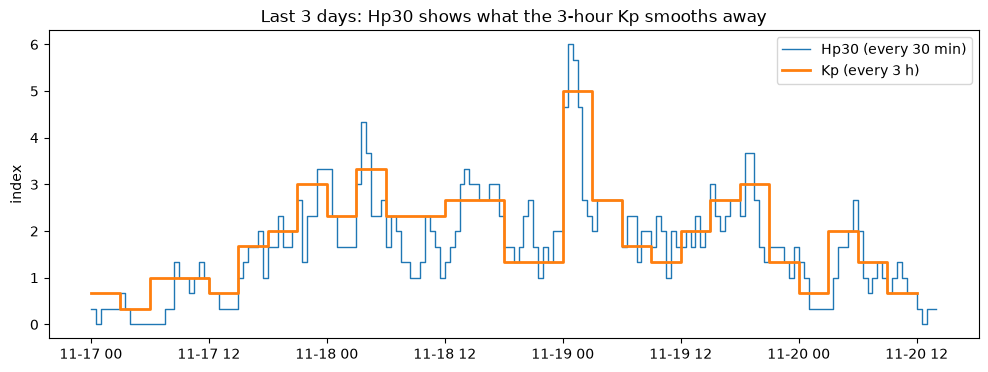

In [6]:
# GFZ Hp30: same idea as Kp, but every 30 minutes and open-ended above 9
t0 = today - pd.Timedelta(days=3)
hp = get_json("https://kp.gfz.de/app/json/", start=t0.strftime("%Y-%m-%dT%H:%M:%SZ"),
              end=pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ"), index="Hp30")
hp30 = pd.DataFrame({"time": pd.to_datetime(hp["datetime"], utc=True), "Hp30": hp["Hp30"]})
kp_3d = kp3[kp3["time"] >= t0]
kp_3d = pd.concat([kp_3d, kp_3d.tail(1).assign(time=lambda d: d["time"] + pd.Timedelta(hours=3))])

fig, ax = plt.subplots(figsize=(12, 4))
ax.step(hp30["time"], hp30["Hp30"], where="post", lw=1, label="Hp30 (every 30 min)")
ax.step(kp_3d["time"], kp_3d["Kp"], where="post", lw=2, label="Kp (every 3 h)")
ax.set(ylabel="index", title="Last 3 days: Hp30 shows what the 3-hour Kp smooths away")
ax.legend()
plt.show()

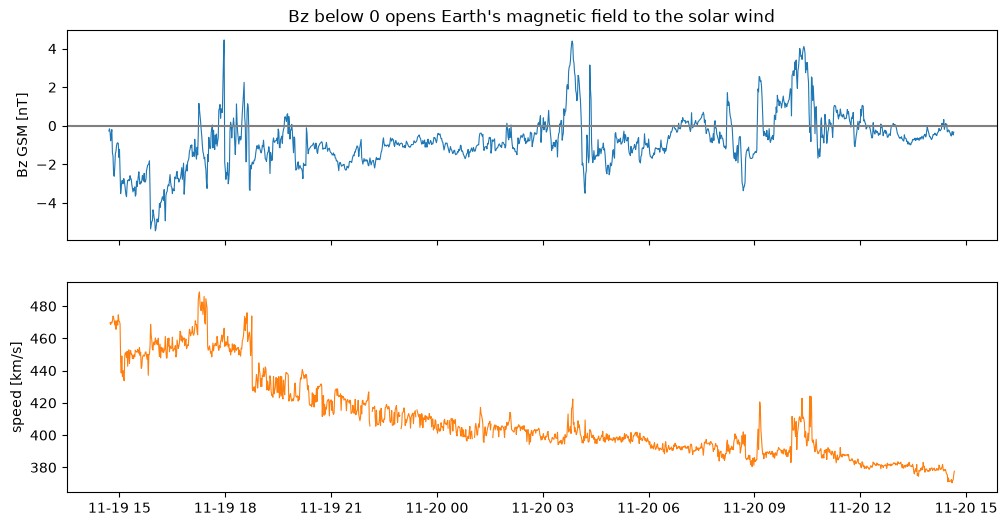

Solar wind now ≈ 378 km/s → arrives at Earth in ≈ 66 min


In [7]:
# solar wind at L1 right now and the resulting warning time
mag = pd.DataFrame(get_json(f"{NOAA}/json/rtsw/rtsw_mag_1m.json"))
wind = pd.DataFrame(get_json(f"{NOAA}/json/rtsw/rtsw_wind_1m.json"))
mag = mag[mag["active"]].copy()
wind = wind[wind["active"]].copy()
for df in (mag, wind):
    df["time"] = pd.to_datetime(df["time_tag"], utc=True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax1.plot(mag["time"], mag["bz_gsm"], lw=0.8)
ax1.axhline(0, color="grey")
ax1.set(ylabel="Bz GSM [nT]", title="Bz below 0 opens Earth's magnetic field to the solar wind")
ax2.plot(wind["time"], wind["proton_speed"], lw=0.8, color="tab:orange")
ax2.set(ylabel="speed [km/s]")
plt.show()

speed = wind.sort_values("time").tail(60)["proton_speed"].median()
print(f"Solar wind now ≈ {speed:.0f} km/s → arrives at Earth in ≈ {1.5e6 / speed / 60:.0f} min")

### What the live data shows

- The official Kp is a flat step for 3 hours, the minute estimate and Hp30 move inside it → finer data already exists.
- The real limit for a forecast is **the travel time from L1 to Earth**, not the 3 hours of Kp.
- The faster the solar wind, the shorter the warning time – exactly when you need it most.

## 5. Real storms in our data

### Which storms we can look at

| Storm | Year | Strength | Data? |
|---|---|---|---|
| Carrington | 1859 | strongest known storm | **no** – long before any satellite (OMNI starts 1963) |
| Québec blackout | 1989 | Kp 9, 6 million people without power for 9 h | Kp yes, solar wind at L1 almost missing |
| Halloween storms | 2003 | Kp 9 (G5) | yes, but gaps during the peak |
| Starlink loss | 2022 | only Kp 5 (G1), still 38 satellites lost | yes, complete |
| Gannon storm | 2024 | Kp 9 (G5), aurora over all of Germany | yes, best example |

The files come from `Karl/tools/omni_year_to_parquet.py` and live in `_data/<year>/` (not on GitHub, too big).
To get a year: download `omni2_<year>.dat` and `omni_min<year>.asc` from NASA OMNI into `_data/<year>/`, then run
`uv run python Karl/tools/omni_year_to_parquet.py <year>`.

In [8]:
# storm windows and a loader that skips years you have not downloaded yet
DATA = Path("../_data")
STORMS = {
    "Québec 1989":   (1989, "1989-03-12", "1989-03-16"),
    "Halloween 2003": (2003, "2003-10-28", "2003-11-01"),
    "Starlink 2022":  (2022, "2022-02-02", "2022-02-06"),
    "Gannon 2024":    (2024, "2024-05-09", "2024-05-13"),
}

def load_storm(year, start, end):
    path = DATA / str(year) / f"omni_{year}.parquet"
    if not path.exists():
        print(f"missing {path} – see the instructions above")
        return None
    return pd.read_parquet(path, columns=["bz_gsm", "speed", "sym_h", "kp"]).loc[start:end]

storms = {name: df for name, args in STORMS.items() if (df := load_storm(*args)) is not None}
pd.DataFrame({name: {"max Kp": df["kp"].max(), "min Bz [nT]": df["bz_gsm"].min(),
                     "max speed [km/s]": df["speed"].max(), "min SYM-H [nT]": df["sym_h"].min(),
                     "solar wind data present": f"{df['bz_gsm'].notna().mean():.0%}"}
              for name, df in storms.items()})

,Québec 1989,Halloween 2003,Starlink 2022,Gannon 2024
max Kp,9.0,9.0,5.3,9.0
min Bz [nT],-16.639999,-29.32,-18.860001,-47.849998
max speed [km/s],862.700012,1121.5,636.700012,1025.900024
min SYM-H [nT],-720.0,-432.0,-80.0,-518.0
solar wind data present,18%,53%,99%,86%


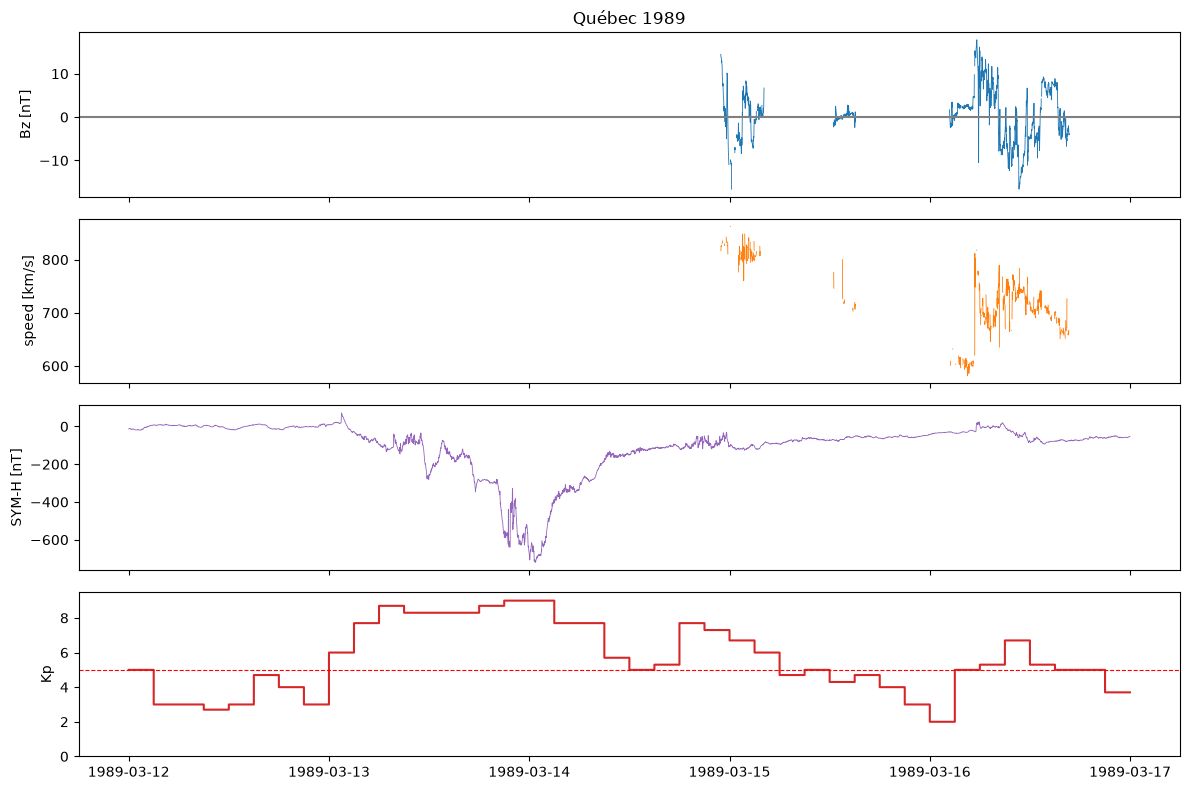

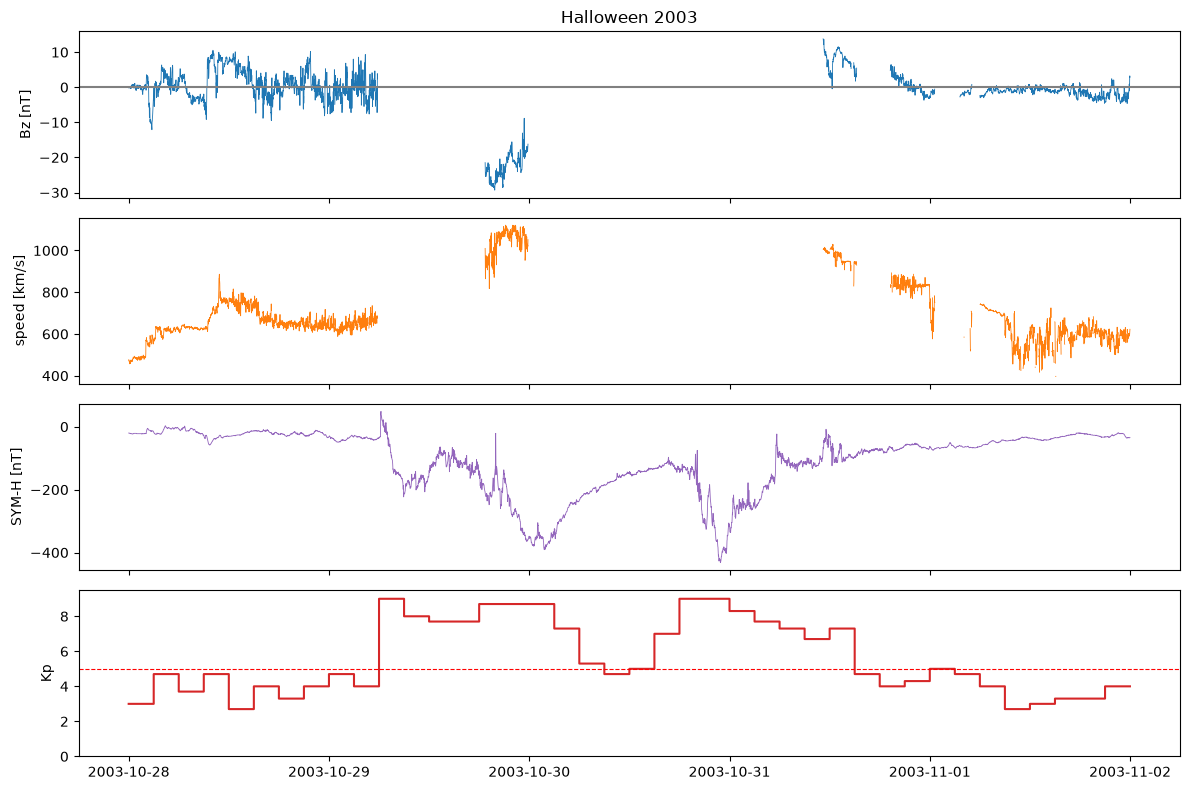

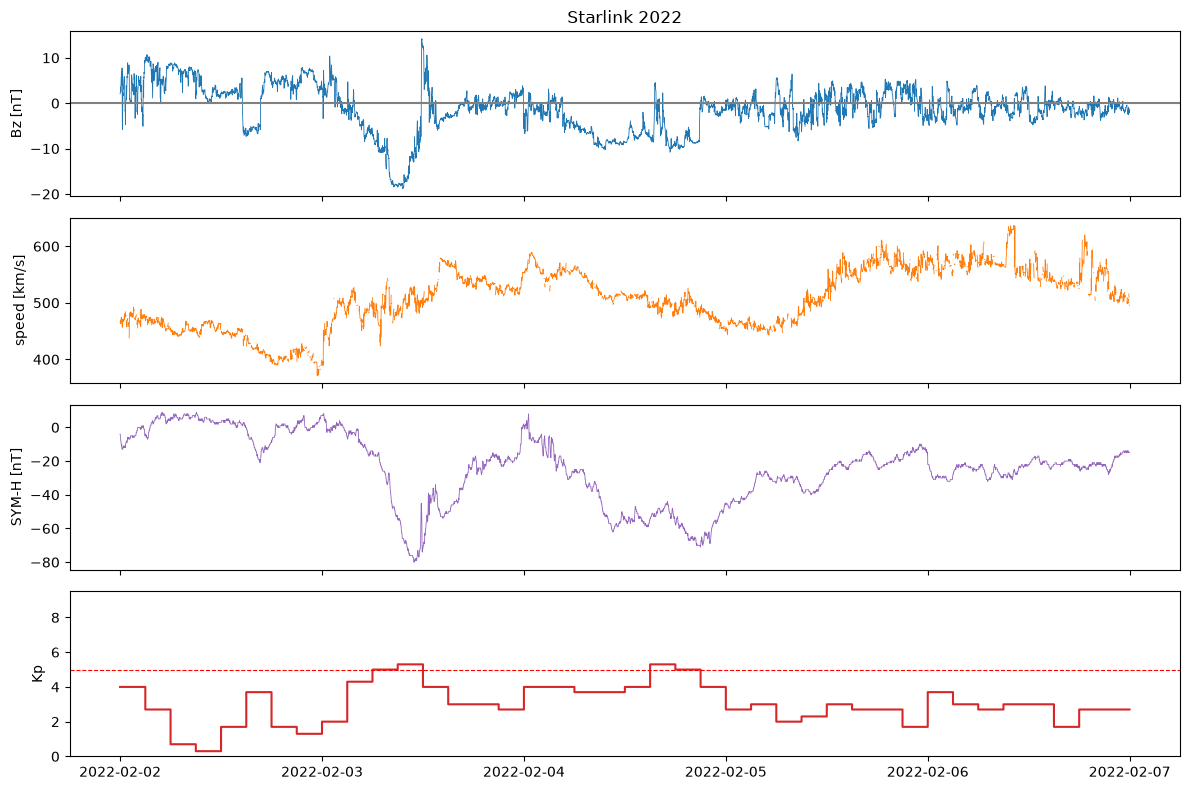

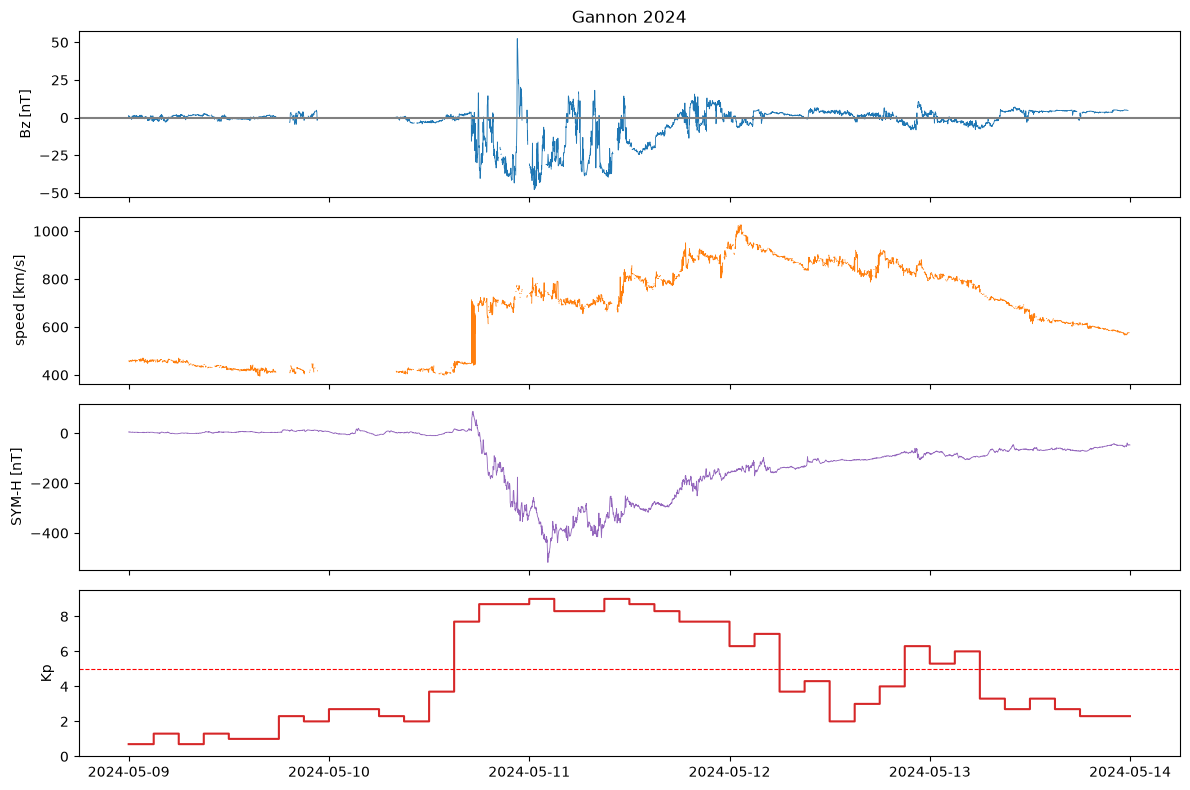

In [9]:
# each storm: Bz turns south, speed jumps, SYM-H drops, Kp climbs
for name, df in storms.items():
    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    axes[0].plot(df.index, df["bz_gsm"], lw=0.6)
    axes[0].axhline(0, color="grey")
    axes[0].set_ylabel("Bz [nT]")
    axes[1].plot(df.index, df["speed"], lw=0.6, color="tab:orange")
    axes[1].set_ylabel("speed [km/s]")
    axes[2].plot(df.index, df["sym_h"], lw=0.6, color="tab:purple")
    axes[2].set_ylabel("SYM-H [nT]")
    axes[3].step(df.index, df["kp"], where="post", color="tab:red")
    axes[3].axhline(5, color="red", ls="--", lw=0.8)
    axes[3].set(ylabel="Kp", ylim=(0, 9.5))
    axes[0].set_title(name)
    plt.tight_layout()
    plt.show()

### What the storms show

- Every big storm starts with **Bz turning strongly south** and a **jump in speed** at L1.
- **SYM-H** (minute version of Dst) drops shortly after – this is the reaction on Earth.
- Kp climbs to 9 in 1989, 2003 and 2024. In 2022 it only reaches 5.3 (G1), yet 38 Starlink satellites were lost: even a small storm is expensive if nobody plans for it.
- Gaps (1989, 2003) show a real problem: during extreme storms the instruments themselves fail. A model has to cope with missing data.

## 6. What our model does

### Inputs, target, first results

| | |
|---|---|
| **Input (features)** | solar wind at L1 every minute: `bz_gsm`, `speed`, `density`, `pressure`, `b_sum`, slopes, … |
| **Target** | Kp (later maybe Hp30: finer and not capped at 9) |
| **Horizon** | the next 30–60 minutes – limited by the L1 → Earth travel time |
| **Data** | OMNI since 1995 (`omni_1995.parquet`, built in `SolarSentinel.ipynb`) |
| **Baseline** | `DummyRegressor` (always the average) vs **LightGBM** – metrics R², MAE, RMSE |
| **Next** | pretrained time-series models: `SolarSentinel_cronos.ipynb` (Chronos), `SolarSentinel_patchTsT.ipynb` (PatchTST) |

### Things to keep in mind

- **Imbalanced data:** 90 %+ of the time Kp < 5. Without countermeasures the model learns mostly "calm" – but storms are what matters.
- **Missing data:** exactly in the strongest storms the solar wind data has gaps (section 5).
- **Warning time shrinks in big storms:** fast solar wind = less time between L1 and Earth.
- **Open question:** does `5-` (4.67) already count as a storm (G1)?

## 7. Sources

### Where the facts come from

- NOAA SWPC – Space Weather Scales: https://www.swpc.noaa.gov/noaa-scales-explanation
- GFZ Potsdam – Kp and Hp30: https://kp.gfz.de
- NASA OMNI data: https://spdf.gsfc.nasa.gov/pub/data/omni
- USGS – May 10, 2024 storm: https://www.usgs.gov/programs/geomagnetism/science/may-10-2024-magnetic-disturbance
- Hydro-Québec – March 1989 storm: https://www.hydroquebec.com/learning/notions-de-base/tempete-mars-1989.html
- Parker & Linares (2024), satellite drag in the May 2024 storm: https://arxiv.org/abs/2406.08617

Not double-checked yet (from general knowledge): Carrington CME travel time ~17.6 h, Kp threshold for aurora in Germany.